# 2. Two-site population dynamics

**Author:** Aditya Banerjee  
**Thesis:** *Linear Anyon Model with Rydberg Atoms*, Universitat de Barcelona, 2026

A static effective Hamiltonian evolves each initial occupation state into the others allowed by its number sector. The thesis interprets these curves as the effective, stroboscopic dynamics; rapid micromotion and losses are outside this closed model.

**Thesis source:** Sections 3.8–3.8.1, Eqs. (48)–(55), Figure 3. Descriptions below are adapted from these sections;
equation numbers refer to the thesis. **Code source:** [`heff2_states.py`](../scripts/heff2_states.py).

**Steps:** parameters → Stark shifts → exchange matrix → time evolution → six initial states → analytic check.

Run the numbered sections from top to bottom. Longer derivations and implementation
comparisons are at the end. These are theoretical calculations, not experimental data.

## 1. Import libraries

In [1]:
%matplotlib inline
from pathlib import Path
from itertools import product
import numpy as np
from scipy.special import jv
import matplotlib.pyplot as plt
from IPython.display import display

np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})

In [2]:
# Run from the repository root or from notebooks/.
here = Path.cwd().resolve()
ROOT = next(p for p in [here, *here.parents] if (p / "scripts").is_dir() and (p / "data").is_dir())
DATA = ROOT / "data"
SAVE_FIGURES = False
STYLE = {"font.size": 11}


def show_figure(fig, name):
    if SAVE_FIGURES:
        destination = ROOT / "notebook_outputs"
        destination.mkdir(exist_ok=True)
        fig.savefig(destination / f"{name}.png", dpi=160)
    display(fig)
    plt.close(fig)

## 2. Set parameters and list the basis states

**Symbols used in the code**

| Thesis symbol | Code name | Meaning |
|---|---|---|
| $C_{ab}$ | `C00`, `C01`, … | Interaction-shift parameters |
| $\Omega_\alpha,\Omega_\beta$ | `Om_a`, `Om_b` | Laser-coupling amplitudes |
| $\omega'$ | `wp` or `WP` | Drive rate |
| $A$ | `A` | Detuning-modulation amplitude |
| $\kappa=A/\omega'$ | `kappa` or `kap` | Dimensionless modulation index |
| $L$ | `L` | Number of sites |
| $N$ | `N` | Total occupation quanta |

The bare pair energies are $2C_{00},C_{01},2C_{11},C_{02},C_{12},2C_{22}$.
The $C$, $\Omega$, $\omega'$, and $A$ values use one **native numerical rate unit**.
$J_\ell(\kappa)$ is the Bessel function of integer order $\ell$.

Evolution uses $K=H/(\hbar\omega_{\rm ref})$ and $\tau=\omega_{\rm ref}t$,
with $[\hbar\omega_{\rm ref}]={\rm J}$ and $[\tau]=1$; the reference is one
native rate unit. This preserves the source numbers without claiming a calibrated
microsecond axis while the cycles-versus-radians convention remains unresolved.

In [3]:
hbar = 1.0
C00, C01, C11 = 0.0, 20.0, 15.0
C02, C12, C22 = 2 * C11, 45.0, 55.0
Om_a, Om_b = 1.0, 1.0
alpha, beta = np.pi / 4, np.pi / 3
wp, A = 40.0, 48.0
kappa = A / wp
nt0, nt1 = -40.0, -40.0
COMPENSATE_11BLOCK = True
LMAX = 40
ells = np.arange(-LMAX, LMAX + 1)
Jl = jv(ells, kappa)

In [4]:
N0 = (2 * C11 - C02 - nt0) / wp
N1 = (2 * C11 - C02 - nt1) / wp
q = (nt1 - nt0) / wp


def is_int(x, tol=1e-9):
    return abs(x - round(x)) < tol


labels = ["00", "01", "02", "10", "11", "12", "20", "21", "22"]
idx = {s: i for i, s in enumerate(labels)}
DIM = 9

## 3. Calculate the AC Stark shifts

Thesis Eqs. (41)–(42) give the diagonal matrix entries.
The two detunings $\widetilde\nu_0,\widetilde\nu_1$ are `nt0`, `nt1`.
The source sideband sum below has inverse-rate units.

In [5]:
def stark_sum(dconst, nu):
    denom = dconst + nu + ells * wp
    if np.any(np.abs(denom) < 1e-9):
        raise ZeroDivisionError(f"resonant Stark denominator (dconst={dconst}, nu={nu})")
    return np.sum(Jl**2 / denom)

In [6]:
E = {}
E["00"] = -2 * Om_a**2 / (C01 - 2 * C00)
E["01"] = (
    Om_a**2 / (C01 - 2 * C00) - Om_a**2 / (2 * C11 - C01) - Om_b**2 * stark_sum(C02 - C01, nt1)
)
E["02"] = Om_b**2 * stark_sum(C02 - C01, nt1) - Om_a**2 / (C12 - C02)
E["10"] = (
    Om_a**2 / (C01 - 2 * C00) - Om_a**2 / (2 * C11 - C01) - Om_b**2 * stark_sum(C02 - C01, nt0)
)
E["11"] = (
    2 * Om_a**2 / (2 * C11 - C01)
    - Om_b**2 * stark_sum(C12 - 2 * C11, nt0)
    - Om_b**2 * stark_sum(C12 - 2 * C11, nt1)
)
E["12"] = (
    Om_a**2 / (C12 - C02)
    + Om_b**2 * stark_sum(C12 - 2 * C11, nt1)
    - Om_b**2 * stark_sum(2 * C22 - C12, nt0)
)
E["20"] = Om_b**2 * stark_sum(C02 - C01, nt0) - Om_a**2 / (C12 - C02)
E["21"] = (
    Om_a**2 / (C12 - C02)
    + Om_b**2 * stark_sum(C12 - 2 * C11, nt0)
    - Om_b**2 * stark_sum(2 * C22 - C12, nt1)
)
E["22"] = Om_b**2 * stark_sum(2 * C22 - C12, nt0) + Om_b**2 * stark_sum(2 * C22 - C12, nt1)

**Source assumption.** The script imposes $E_{11}=E_{20}$ by adding a diagonal shift.
We retain the operation, while distinguishing it from recomputing the microscopic detunings.

In [7]:
delta_comp = (E["20"] - E["11"]) if COMPENSATE_11BLOCK else 0.0
E["11"] += delta_comp
print("Imposed |11> shift:", delta_comp)

Imposed |11> shift: -0.2702366491755135


## 4. Build the nine-state Hamiltonian

Use the four exchange processes of Eq. (43).
`add_coupling` writes both a transition and its complex conjugate, so $H=H^\dagger$.
The parameters $N_0,N_1,q$ in Eq. (44) must be integers for the corresponding terms to survive.

In [8]:
H = np.zeros((DIM, DIM), dtype=complex)
for s in labels:
    H[idx[s], idx[s]] = E[s]


def add_coupling(bra, ket, amp):
    H[idx[bra], idx[ket]] += amp
    H[idx[ket], idx[bra]] += np.conj(amp)

In [9]:
g1 = Om_a**2 * (1.0 / (C01 - 2 * C00) - 1.0 / (2 * C11 - C01))  # |01><->|10>
add_coupling("10", "01", g1 * np.exp(-1j * alpha))

pref = Om_a * Om_b * (1.0 / (2 * C11 - C01) - 1.0 / (C12 - C02))
g2 = pref * jv(round(N0), kappa) if is_int(N0) else 0.0  # |11><->|20>
if g2:
    add_coupling("20", "11", g2 * np.exp(1j * (beta - 2 * alpha)))
g3 = pref * jv(round(N1), kappa) if is_int(N1) else 0.0  # |02><->|11>
if g3:
    add_coupling("11", "02", g3 * np.exp(1j * (alpha - 2 * beta)))
if is_int(q):  # |12><->|21>
    qi = round(q)
    Sig = 1.0 / (C12 - 2 * C11 + nt0 + ells * wp) - 1.0 / (2 * C22 - C12 + nt0 + ells * wp)
    g4 = Om_b**2 * np.sum(Jl * jv(ells - qi, kappa) * Sig)
    add_coupling("21", "12", g4 * np.exp(-1j * beta))
else:
    g4 = 0.0
assert np.allclose(H, H.conj().T)

## 5. Define time evolution

The thesis starts from
$$|\psi(t)\rangle=e^{-iH_{\rm eff}^{(2)}t}|\psi(0)\rangle\qquad\text{[Eq. (48), }\hbar=1\text{]}.$$
In our declared numerical convention the code argument `t` is dimensionless $\tau$.
Diagonalizing $K=V\operatorname{diag}(\lambda)V^\dagger$ evaluates the exponential.
The output is $P_s=|\langle s|\psi\rangle|^2$, with $\sum_sP_s=1$.

In [10]:
evals, evecs = np.linalg.eigh(H)


def evolve(psi0, t):
    c = evecs.conj().T @ psi0
    return np.abs((np.exp(-1j * np.outer(t, evals) / hbar) * c) @ evecs.T) ** 2


def ket(s):
    v = np.zeros(DIM, dtype=complex)
    v[idx[s]] = 1.0
    return v

## 6. Choose the initial states and calculate populations

The original Figure 3 contains six panels. Here all six use the source functions and their own time window.

In [11]:
def two_level(Ea, Eb, g):
    d = 0.5 * (Ea - Eb)
    Om = np.hypot(abs(g), d)
    return (abs(g) ** 2 / (abs(g) ** 2 + d**2) if Om > 0 else 0.0), (
        np.pi / Om if Om > 0 else np.inf
    )


p_ex, T_ex = two_level(E["01"], E["10"], g1)
p_f, T_f = two_level(E["11"], E["20"], g2)
p_cs, T_cs = two_level(E["12"], E["21"], g4)
panels = [
    ("01", ["01", "10"], 4 * T_ex),
    ("10", ["10", "01"], 4 * T_ex),
    ("11", ["11", "20", "02"], 4 * T_f),
    ("12", ["12", "21"], 4 * T_cs),
    ("21", ["21", "12"], 4 * T_cs),
    ("22", ["22"], 4 * T_cs),
]
traces = [(init, watch, np.linspace(0, end, 1000)) for init, watch, end in panels]
populations = [evolve(ket(init), tau) for init, watch, tau in traces]
print("Calculated", len(populations), "initial-state trajectories.")

Calculated 6 initial-state trajectories.


## 7. Plot the population dynamics

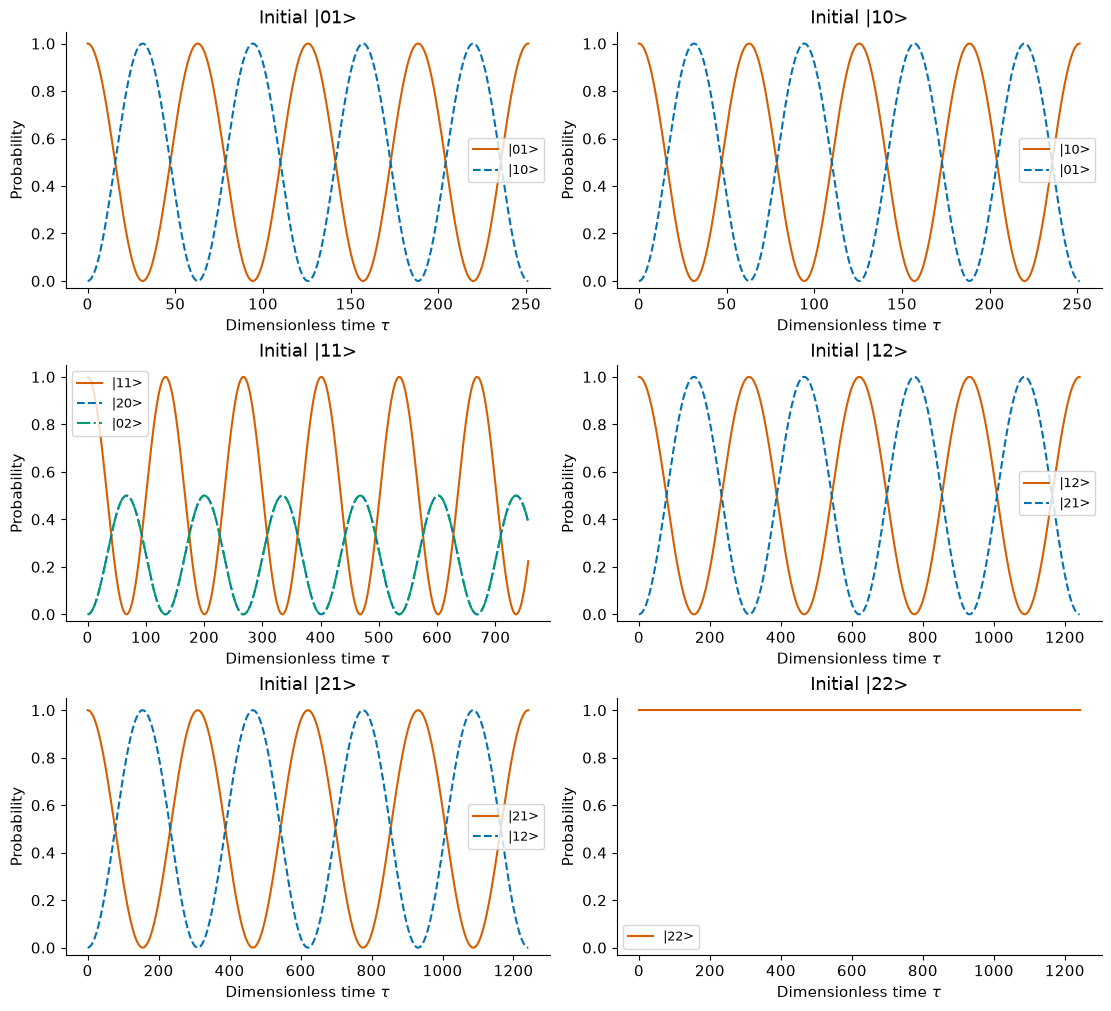

In [12]:
fig, axes = plt.subplots(3, 2, figsize=(11, 10), layout="constrained")
for ax, (init, watch, tau), population in zip(axes.flat, traces, populations):
    for state, colour, style in zip(watch, ["#D55E00", "#0072B2", "#009E73"], ["-", "--", "-."]):
        ax.plot(tau, population[:, idx[state]], color=colour, linestyle=style, label=f"|{state}>")
    ax.set(
        title=f"Initial |{init}>",
        xlabel=r"Dimensionless time $\tau$",
        ylabel="Probability",
        ylim=(-0.03, 1.05),
    )
    ax.legend(fontsize=9)
show_figure(fig, "02_populations")

## 8. Interpret the oscillations and check the solution

The $N=1$ and $N=3$ manifolds exchange two states.
The $N=2$ manifold has both $|02\rangle$ and $|20\rangle$ coupled to $|11\rangle$;
it is a three-state problem. The isolated $|22\rangle$ state stays stationary.
For a two-state block, the source gives [Eq. (50)]
$$P_{10}(\tau)=\frac{4|g_1|^2}{\Delta^2+4|g_1|^2}
\sin^2\!\left(\frac{\tau}{2}\sqrt{\Delta^2+4|g_1|^2}\right),\quad
\Delta=E_{01}-E_{10}.$$
Here $\Delta$ is the **full** diagonal difference; it is twice the half-detuning used in the appendix.

In [13]:
tau = traces[0][2]
delta = E["01"] - E["10"]
frequency = np.sqrt(delta**2 + 4 * abs(g1) ** 2)
analytic = 4 * abs(g1) ** 2 / frequency**2 * np.sin(frequency * tau / 2) ** 2
error = np.max(abs(populations[0][:, idx["10"]] - analytic))
assert error < 1e-12
for probability in populations:
    np.testing.assert_allclose(probability.sum(axis=1), 1, atol=1e-12)
print("Two-state probability error:", error)
print("Probability conservation for all six trajectories: PASS")

Two-state probability error: 1.7208456881689926e-15
Probability conservation for all six trajectories: PASS


## Appendix — detailed derivations and verification

The main calculation is complete. This appendix retains the symbolic steps, conventions, limiting cases, and source comparisons for closer study.

### Conventions, dimensions, and evidence status

**Theoretical model:** each site has the orthonormal occupation basis
$|0\rangle,|1\rangle,|2\rangle$. The tensor-product basis is lexicographic,
with the leftmost site the most significant index. Occupations above two are
excluded. State vectors have norm one; probabilities and occupation numbers
are dimensionless. Chains use open boundaries unless explicitly stated.
This is a nonrelativistic finite-dimensional calculation; no spacetime metric
signature is used. Finite sums replace spatial integration, and no continuum
boundary conditions are assumed.

Start with physical energy $H$ and positive reference angular frequency
$\omega_{\rm ref}$. Define
$$K=\frac{H}{\hbar\omega_{\rm ref}},\qquad
  \tau=\omega_{\rm ref}t,\qquad \hbar=\frac{h}{2\pi}.$$
Since $[H]={\rm J}$ and $[\hbar\omega_{\rm ref}]={\rm J\,s}\,{\rm s}^{-1}
={\rm J}$, $K$ is dimensionless. Likewise $[\tau]={\rm s}^{-1}{\rm s}=1$.
Schrödinger evolution becomes
$$i\hbar\,\omega_{\rm ref}\frac{d\psi}{d\tau}
   =\hbar\omega_{\rm ref}K\psi,
  \qquad i\frac{d\psi}{d\tau}=K\psi.$$

**Unresolved source convention:** archived scripts label numerical rates as
MHz while using the numerical matrix in $\exp(-iEt)$; a header also equates MHz with rad/us.
Appendix B of the thesis writes $\omega'/2\pi$ in MHz. If a matrix is supplied
as $H/h$ in cycles per unit time, its propagator is $\exp[-i2\pi(H/h)t]$;
if supplied as $H/\hbar$, it is $\exp[-i(H/\hbar)t]$. Dimensional analysis
cannot distinguish these two conventions. The notebooks therefore preserve
native numerical values and use $\tau$, without claiming a calibrated
microsecond axis. Any physical conversion requires a declared convention.
For the effective-model numerical cells, the reference is one native rate
unit: a rate divided by that reference has the same numerical value.
Thus the arrays used in the propagator are dimensionless $K$, even when
the source-formula coefficients are described below as native rates.

**Source-backed numerical facts** refer to the archived files and checks
shown here. They are not experimental observations. **Physical reachability**
and **proposed extensions** are labelled separately. See
[scientific notes](../SCIENTIFIC_NOTES.md) for unresolved interpretations.

### 2.2 Derive the propagator before evaluating it

Let the orthonormal eigenvectors satisfy $Kv_m=\lambda_m v_m$. Form the
unitary matrix $V=(v_0,v_1,\ldots)$ so that $V^\dagger V=I$ and
$K=V\Lambda V^\dagger$. Expand the normalized initial state:
$$c_m=v_m^\dagger\psi(0),\qquad
  \psi(0)=\sum_m c_m v_m.$$
Inserting this into $i\,d\psi/d\tau=K\psi$ gives an equation for each
coefficient: $i\,dc_m(\tau)/d\tau=\lambda_m c_m(\tau)$.
Its solution with boundary value $c_m(0)=c_m$ is
$$c_m(\tau)=e^{-i\lambda_m\tau}c_m,\qquad
  \psi(\tau)=\sum_m e^{-i\lambda_m\tau}v_m v_m^\dagger\psi(0).$$
Every exponent is dimensionless. Projection onto basis state $s$ gives
$$P_s(\tau)=|\langle s|\psi(\tau)\rangle|^2.$$
Since $|e^{-i\lambda_m\tau}|=1$ for real $\lambda_m$,
$\sum_sP_s=\sum_m|c_m|^2=1$. There is no loss or decoherence term in this model.

### 2.3 A two-state solution for the isolated exchange blocks

For two states $a,b$, subtract the common diagonal energy
$\bar\epsilon=(\epsilon_a+\epsilon_b)/2$. This produces only a global phase.
Set $\delta=(\epsilon_a-\epsilon_b)/2$ and write
$$K'=\begin{pmatrix}\delta&g^*\\g&-\delta\end{pmatrix}.$$
Multiplication gives
$$K'^2=\begin{pmatrix}\delta^2+|g|^2&\delta g^*-g^*\delta\\
  g\delta-\delta g&|g|^2+\delta^2\end{pmatrix}
  =(\delta^2+|g|^2)I.$$
Put $q=\sqrt{\delta^2+|g|^2}$. Separate even and odd powers of the exponential:
$$e^{-iK'\tau}=I\cos(q\tau)-i\frac{K'}q\sin(q\tau).$$
The off-diagonal transition amplitude from $a$ to $b$ is
$-ig\sin(q\tau)/q$, so
$$P_{a\to b}(\tau)=\frac{|g|^2}{|g|^2+\delta^2}
   \sin^2\!\left(\sqrt{|g|^2+\delta^2}\,\tau\right).$$
On resonance ($\delta=0$), the transfer can reach one. For $|g|\to0$ at fixed
nonzero $\delta$, its amplitude tends to zero. If both vanish, $K'=0$ and the
state is stationary; use this limit instead of dividing by zero.

### 2.4 Resonant three-state check

If the three diagonals are equal, $|11\rangle$ couples to a normalized bright
combination of the two outer states, with total strength
$G=\sqrt{|g_2|^2+|g_3|^2}$. The orthogonal outer-state combination is dark.
For explicit phases, define the two center-to-outer matrix elements
$t_{20}=g_2e^{i\vartheta_2}$ and $t_{02}=g_3e^{-i\vartheta_3}$.
After subtracting the equal diagonal, the three-state matrix is
$$K'=t_{20}|20\rangle\langle11|+t_{02}|02\rangle\langle11|+\mathrm{h.c.}$$
For $G>0$, the bright and dark states are
$$|B\rangle=\frac{t_{20}|20\rangle+t_{02}|02\rangle}{G},\qquad
  |D\rangle=\frac{t_{02}^*|20\rangle-t_{20}^*|02\rangle}{G}.$$
Their overlap is
$$\langle B|D\rangle=
  \frac{t_{20}^*t_{02}^*-t_{02}^*t_{20}^*}{G^2}=0.$$
Direct application gives $K'|11\rangle=G|B\rangle$,
$K'|B\rangle=G|11\rangle$, and $K'|D\rangle=0$.
The active two-state block is consequently
$\begin{pmatrix}0&G\\G&0\end{pmatrix}$ in the basis
$(|11\rangle,|B\rangle)$. The preceding two-state derivation gives
$$|\psi(\tau)\rangle=\cos(G\tau)|11\rangle-i\sin(G\tau)|B\rangle.$$
For $G=0$, the initial state is stationary and $B,D$ need not be defined.
Starting in $|11\rangle$ therefore gives
$$P_{11}(\tau)=\cos^2(G\tau),\quad
  P_{20}(\tau)=\frac{|g_2|^2}{G^2}\sin^2(G\tau),\quad
  P_{02}(\tau)=\frac{|g_3|^2}{G^2}\sin^2(G\tau).$$
The two outer probabilities add to $\sin^2(G\tau)$, so normalization is
explicit. For equal magnitudes, each outer state can receive at most one half
from this initial state. This statement assumes exact equal diagonals and
no extra couplings; it is not the detuned three-state solution.

### Compare the notebook calculation with the validated reference

The following cell is an implementation check. The main calculation above contains its own code and does not require these reference imports.

In [14]:
import sys

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from anyon_thesis.models import EffectiveParameters, effective_bond, effective_chain, phase_pattern
from dataclasses import replace

parameters = replace(EffectiveParameters(), sideband_cutoff=LMAX)
diagonal, rates, _ = effective_bond(parameters)
reference_H, _ = effective_chain(
    2, diagonal, rates, phase_pattern("laser_pair", alpha=alpha, beta=beta)
)
np.testing.assert_allclose(H, reference_H, atol=1e-13)
G = np.hypot(abs(g2), abs(g3))
P = evolve(ket("11"), tau)
np.testing.assert_allclose(P[:, idx["11"]], np.cos(G * tau) ** 2, atol=1e-12)
print("Original nine-state matrix and resonant three-state identity: PASS")

Original nine-state matrix and resonant three-state identity: PASS


### Sources and adaptations

- [Read the thesis](https://hdl.handle.net/2445/231684); thesis equation numbers are identified beside their use.
- Original calculation code: [`heff2_states.py`](../scripts/heff2_states.py), source commit `22959963191fcbc4d283ec4b272b506ad6dd979b`.
- [Scientific notes](../SCIENTIFIC_NOTES.md): frequency convention, imposed compensation, physical phase reachability, and finite-size interpretation.
- [Validation and adaptation record](VALIDATION.md).
- Notebook layout follows the short, numbered explanation–code–output pattern of the
  [AQI example](https://github.com/Charub17/global-air-pollution-aqi-ml/blob/main/Global_Air_Pollution_AQI_ML.ipynb).
  Its prose, data analysis, and numerical claims are not reused.

The code cells retain the source calculations. Notebook-specific adaptations are
labelled beside the relevant cell. No large archived job is launched implicitly.